# Step 4 · Driver ratings, chains and car pace

**Inputs:** `data/teammate_gaps.csv`, `qualifying_clean.csv` (from `data.ipynb`)
**Outputs:** `data/driver_ratings.csv`, `data/chain_backtest.csv`, `data/car_pace.csv`, `data/car_pace_pairs.csv`, three figures

What this notebook does:
1. Checks how connected the teammate network is (why short chains alone are not enough).
2. Rates every driver against George Russell (= 0) with a 95% interval, using all teammate links at once (weighted least squares, the same idea as Eq. 4).
3. Backtests chaining: hides each real teammate pair and checks whether the chain predicts their gap.
4. Estimates each car's qualifying pace with the driver effect removed (Eq. 5) and sanity-checks it.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.colors import LinearSegmentedColormap

from f1_stats import (load_gaps, pair_season_table, pair_gap, estimate_tau2, chain, find_file,
                      fit_ratings, predicted_gap, session_gap_to_fastest, iqr_mean,
                      setup_plot_style, short, PAIR_SEASON, REFERENCE, TEAM_LINEAGE,
                      BLUE, MUTED, INK, BLUE_RAMP)

setup_plot_style()
os.makedirs('data', exist_ok=True)
os.makedirs('figures', exist_ok=True)

gaps = load_gaps()
ps = pair_season_table(gaps)
usable = ps[ps['usable']]
tau2, _ = estimate_tau2(ps)
print(f'{len(usable)} usable pair-seasons, tau^2 = {tau2:.4f}')

137 usable pair-seasons, tau^2 = 0.0148


## 1. How connected is the teammate network?

Drivers are nodes; two drivers are linked if they were teammates for at least 8 sessions in a season.
The report allowed chains of at most 3 links within 2 seasons. This cell shows why that rule alone cannot rate most of the grid.

In [2]:
def network(years):
    g = nx.Graph()
    sub = usable[usable['year'].isin(list(years))]
    g.add_edges_from(zip(sub['A'], sub['B']))
    return g

full = network(range(2014, 2027))
groups = sorted(nx.connected_components(full), key=len, reverse=True)
print(f'All seasons: {full.number_of_nodes()} drivers in {len(groups)} groups, sizes {[len(c) for c in groups]}')
for c in groups[1:]:
    print('   never linked to the rest:', ', '.join(short(d) for d in sorted(c)))
for window in [(2025, 2026), (2024, 2025)]:
    g = network(range(window[0], window[1] + 1))
    size = len(nx.node_connected_component(g, REFERENCE)) if REFERENCE in g else 0
    print(f'Using only {window[0]}-{window[1]}: Russell is linked to {size} drivers (including himself)')
print('Shortest chain Russell -> Verstappen (all seasons):',
      ' -> '.join(short(d) for d in nx.shortest_path(full, REFERENCE, 'max-verstappen')))

All seasons: 57 drivers in 3 groups, sizes [53, 2, 2]
   never linked to the rest: Bianchi, Chilton
   never linked to the rest: Merhi, Stevens
Using only 2025-2026: Russell is linked to 2 drivers (including himself)
Using only 2024-2025: Russell is linked to 11 drivers (including himself)
Shortest chain Russell -> Verstappen (all seasons): Russell -> Latifi -> Albon -> Verstappen


## 2. Driver ratings: all chains at once (weighted least squares)

Each usable pair-season k gives one equation:

  mean gap of k = θ_A − θ_B + error, with error variance SE_k² + τ² · |season gap to the target season|

θ is a driver's rating = their % gap to Russell (θ_Russell = 0; negative = faster than Russell).
Solving all equations together by **weighted least squares** (weight = 1 / variance):
- uses every chain between two drivers, not just one path, so it averages them;
- down-weights older seasons by m·τ², exactly the drift term of Eq. 4;
- gives each rating a standard error, so every rating has a 95% interval.

Short chains (notebook 03) are kept as the hand-checkable version; section 3 compares the two.

In [3]:
rows = []
for year in range(2014, 2027):
    fit = fit_ratings(ps, year, tau2)                  # Russell = 0
    raced = set(gaps.loc[gaps['year'] == year, 'A']) | set(gaps.loc[gaps['year'] == year, 'B'])
    for d in sorted(raced & set(fit['theta'].index)):
        se = float(np.sqrt(fit['cov'].loc[d, d]))
        rows.append({'year': year, 'driver': d, 'rating': fit['theta'][d], 'se': se,
                     'ci_low': fit['theta'][d] - 1.96 * se, 'ci_high': fit['theta'][d] + 1.96 * se})
ratings = pd.DataFrame(rows)
print(f'{len(ratings)} driver-season ratings')
ratings[ratings['year'] == 2025].sort_values('rating').round(3)

279 driver-season ratings


,year,driver,rating,se,ci_low,ci_high
250,2025,max-verstappen,-0.406,0.160,-0.719,-0.092
244,2025,isack-hadjar,-0.261,0.213,-0.678,0.156
247,2025,lando-norris,-0.155,0.194,-0.536,0.226
238,2025,charles-leclerc,-0.113,0.105,-0.319,0.094
249,2025,liam-lawson,-0.094,0.223,-0.531,0.342
253,2025,oscar-piastri,-0.091,0.199,-0.481,0.298
237,2025,carlos-sainz-jr,-0.075,0.129,-0.328,0.177
242,2025,gabriel-bortoleto,-0.049,0.217,-0.475,0.377
252,2025,oliver-bearman,-0.036,0.186,-0.401,0.330
243,2025,george-russell,0.000,0.000,0.000,0.000


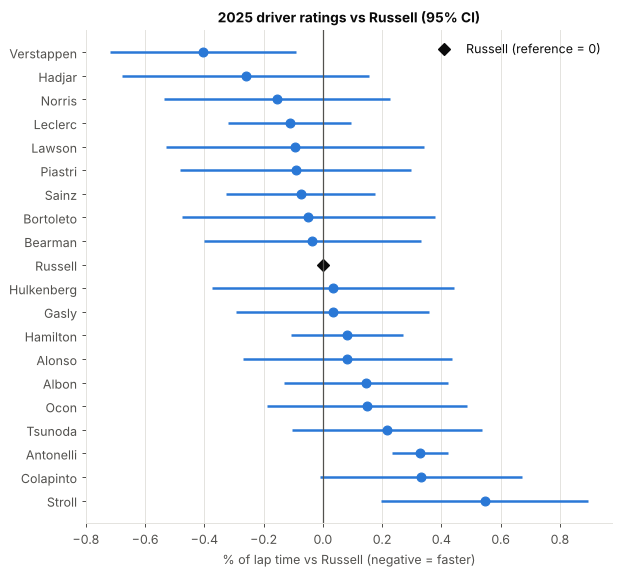

In [4]:
d = ratings[ratings['year'] == 2025].sort_values('rating', ascending=False).reset_index(drop=True)
y = np.arange(len(d))
is_ref = (d['driver'] == REFERENCE).to_numpy()

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.hlines(y, d['ci_low'], d['ci_high'], color=BLUE, linewidth=2)
ax.plot(d.loc[~is_ref, 'rating'], y[~is_ref], 'o', color=BLUE, markersize=7)
ax.plot(d.loc[is_ref, 'rating'], y[is_ref], 'D', color=INK, markersize=7, label='Russell (reference = 0)')
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, [short(x) for x in d['driver']])
ax.grid(axis='y', visible=False)
ax.set_title('2025 driver ratings vs Russell (95% CI)')
ax.set_xlabel('% of lap time vs Russell (negative = faster)')
ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig('figures/driver_ratings_2025.png', bbox_inches='tight')
plt.show()

## 3. Short chain vs full fit: Antonelli vs Hamilton (2025)

In [5]:
link1 = pair_gap(usable, 2025, 'kimi-antonelli', 'george-russell')
link2 = pair_gap(usable, 2024, 'george-russell', 'lewis-hamilton')
g_chain, _, se_chain = chain([(link1['mean'], link1['se']), (link2['mean'], link2['se'])], 1, tau2)
g_fit, se_fit = predicted_gap(fit_ratings(ps, 2025, tau2), 'kimi-antonelli', 'lewis-hamilton')

print(f'Short chain via Russell (Eq. 4): {g_chain:+.2f}%  (95% CI {g_chain - 1.96*se_chain:+.2f} to {g_chain + 1.96*se_chain:+.2f})')
print(f'Full weighted fit:               {g_fit:+.2f}%  (95% CI {g_fit - 1.96*se_fit:+.2f} to {g_fit + 1.96*se_fit:+.2f})')
print('Both say Antonelli was slightly slower; the full fit is tighter because it combines several paths.')

Short chain via Russell (Eq. 4): +0.16%  (95% CI -0.12 to +0.44)
Full weighted fit:               +0.25%  (95% CI +0.04 to +0.46)
Both say Antonelli was slightly slower; the full fit is tighter because it combines several paths.


## 4. Backtest: can chains predict a pair we have never seen?

For every usable pair-season: remove that pair from the data completely (as if they had never been teammates), rebuild the ratings from everyone else, predict their gap, and compare with what really happened.
- **Coverage:** how often the real gap falls inside the 95% interval (target ≈ 95%).
- **Direction:** how often it picks the faster driver (a coin flip is 50%).

In [6]:
rows = []
for r in usable.itertuples():
    fit = fit_ratings(ps, r.year, tau2, drop_pair=(r.A, r.B), reference=r.A)
    pred, se_pred = predicted_gap(fit, r.A, r.B)
    rows.append({'year': r.year, 'team': r.team, 'A': r.A, 'B': r.B, 'actual': r.mean,
                 'se_actual': r.se, 'predicted': pred, 'se_predicted': se_pred})
backtest = pd.DataFrame(rows)
linked = backtest.dropna(subset=['predicted']).copy()
total_se = np.sqrt(linked['se_predicted']**2 + linked['se_actual']**2)
linked['inside_95'] = (linked['actual'] - linked['predicted']).abs() <= 1.96 * total_se
err = linked['actual'] - linked['predicted']

print(f'{len(linked)} of {len(backtest)} hidden pairs could still be linked through other drivers')
print(f"Coverage (real gap inside the 95% interval): {linked['inside_95'].mean():.0%}   (target ~95%)")
print(f"Picks the faster driver: {(np.sign(linked['actual']) == np.sign(linked['predicted'])).mean():.0%}   (coin flip = 50%)")
print(f"MAE of the chained prediction: {err.abs().mean():.2f}   (guessing 0 instead: {linked['actual'].abs().mean():.2f})")

90 of 137 hidden pairs could still be linked through other drivers
Coverage (real gap inside the 95% interval): 81%   (target ~95%)
Picks the faster driver: 71%   (coin flip = 50%)
MAE of the chained prediction: 0.30   (guessing 0 instead: 0.27)


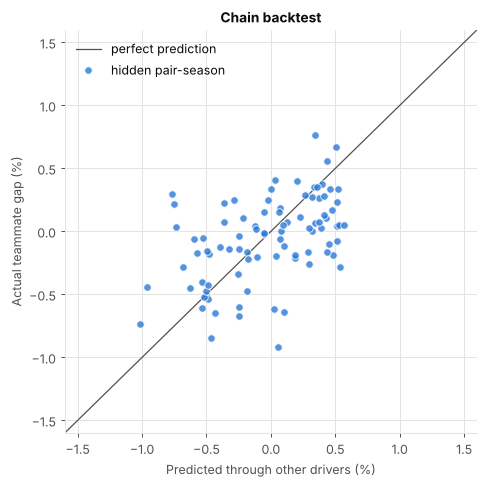

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
lim = 1.6
ax.plot([-lim, lim], [-lim, lim], color=MUTED, linewidth=1, label='perfect prediction')
ax.plot(linked['predicted'], linked['actual'], 'o', color=BLUE, markersize=6, alpha=0.8,
        markeredgecolor='white', markeredgewidth=0.8, label='hidden pair-season')
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel('Predicted through other drivers (%)')
ax.set_ylabel('Actual teammate gap (%)')
ax.set_title('Chain backtest')
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig('figures/chain_backtest.png', bbox_inches='tight')
plt.show()

**How to read this:** chaining usually points the right way (it picks the faster driver well above 50%), but its size estimate for a pair that never shared a car is rough, and the intervals are somewhat too narrow (coverage below 95%). A likely reason: a driver's pace relative to others depends partly on the car (driver–car fit), which a single rating per driver cannot capture. This is a limitation to state in the report.

## 5. Car pace (Eq. 5)

For each pair-session, each driver's gap to the **fastest lap anyone set in the same segment** (Q3 laps vs the fastest Q3 lap, Q1 laps vs the fastest Q1 lap, and so on). Using the same segment keeps both laps in the same track conditions; Q1 laps are slower than Q3 laps, so always comparing with pole would make slower cars look even slower.

Then, per pair-season: P = average of the two drivers' gaps (IQR outliers removed), and

  car pace C = P − ½(θ_A + θ_B)

= how far the car would be from the fastest lap with a Russell-level driver in both seats. Lower = faster car.
Its SE combines the SE of P and the SE of the drivers' average rating.

In [8]:
quali = pd.read_csv(find_file('qualifying_clean.csv'))
gp = session_gap_to_fastest(gaps, quali)
P = gp.groupby(PAIR_SEASON)['P_team'].apply(iqr_mean).unstack().reset_index()
P = P.merge(usable[PAIR_SEASON + ['sessions']], on=PAIR_SEASON)   # usable pair-seasons only

fits = {year: fit_ratings(ps, year, tau2) for year in sorted(P['year'].unique())}
rows = []
for r in P.itertuples():
    th, cov = fits[r.year]['theta'], fits[r.year]['cov']
    if r.A in th.index and r.B in th.index:
        avg_rating = (th[r.A] + th[r.B]) / 2
        var_rating = (cov.loc[r.A, r.A] + cov.loc[r.B, r.B] + 2 * cov.loc[r.A, r.B]) / 4
        rows.append({'year': r.year, 'team': r.team, 'A': r.A, 'B': r.B, 'sessions': r.sessions,
                     'gap_to_fastest': r.mean, 'avg_rating': avg_rating,
                     'car_pace': r.mean - avg_rating, 'car_pace_se': np.sqrt(r.se**2 + var_rating)})
car_pairs = pd.DataFrame(rows)
print(f'Car pace estimated for {len(car_pairs)} of {len(P)} usable pair-seasons')

def combine(d):
    w = d['sessions']
    return pd.Series({'car_pace': np.average(d['car_pace'], weights=w),
                      'se': np.sqrt((w**2 * d['car_pace_se']**2).sum()) / w.sum(),
                      'pairs': len(d)})

car = car_pairs.groupby(['year', 'team']).apply(combine, include_groups=False).reset_index()
car['ci_low'] = car['car_pace'] - 1.96 * car['se']
car['ci_high'] = car['car_pace'] + 1.96 * car['se']
car[car['year'] == 2025].sort_values('car_pace').round(2)

Car pace estimated for 135 of 137 usable pair-seasons


,year,team,car_pace,se,pairs,ci_low,ci_high
116,2025,mercedes,0.31,0.05,1.0,0.21,0.41
115,2025,mclaren,0.32,0.20,1.0,-0.07,0.70
111,2025,aston-martin,0.66,0.19,1.0,0.29,1.03
112,2025,ferrari,0.68,0.11,1.0,0.47,0.90
118,2025,red-bull,0.74,0.17,1.0,0.41,1.07
119,2025,williams,0.82,0.14,1.0,0.55,1.08
113,2025,haas,0.88,0.18,1.0,0.52,1.23
114,2025,kick-sauber,0.94,0.22,1.0,0.52,1.37
110,2025,alpine,0.95,0.18,1.0,0.60,1.29
117,2025,racing-bulls,1.01,0.22,1.0,0.57,1.44


## 6. Sanity check: does the fastest car match reality?

Qualifying pace is not the same as winning the championship (race pace and reliability matter too), but the constructors' champion should be near the front.

In [9]:
champions = {2014: 'mercedes', 2015: 'mercedes', 2016: 'mercedes', 2017: 'mercedes',
             2018: 'mercedes', 2019: 'mercedes', 2020: 'mercedes', 2021: 'mercedes',
             2022: 'red-bull', 2023: 'red-bull', 2024: 'mclaren', 2025: 'mclaren'}
rows = []
for year, champ in champions.items():
    order = car[car['year'] == year].sort_values('car_pace')['team'].tolist()
    rows.append({'year': year, 'fastest car in qualifying': order[0],
                 "constructors' champion": champ,
                 'champion rank': order.index(champ) + 1 if champ in order else None})
check = pd.DataFrame(rows)
print(f"Constructors' champion was fastest or 2nd fastest in {(check['champion rank'] <= 2).sum()} of {len(check)} seasons")
check

Constructors' champion was fastest or 2nd fastest in 12 of 12 seasons


,year,fastest car in qualifying,constructors' champion,champion rank
0,2014,mercedes,mercedes,1
1,2015,mercedes,mercedes,1
2,2016,mercedes,mercedes,1
3,2017,ferrari,mercedes,2
4,2018,ferrari,mercedes,2
5,2019,ferrari,mercedes,2
6,2020,mercedes,mercedes,1
7,2021,mercedes,mercedes,1
8,2022,ferrari,red-bull,2
9,2023,ferrari,red-bull,2


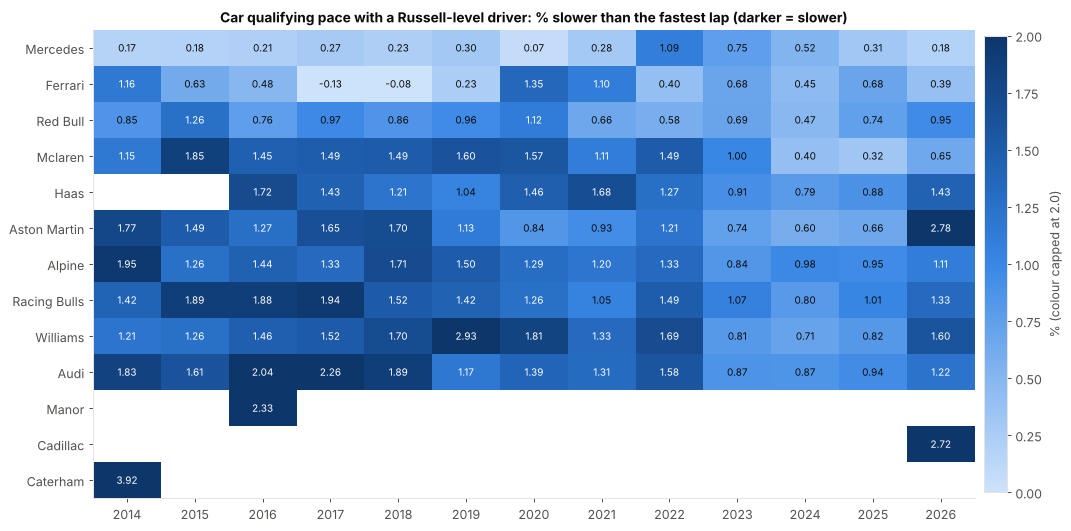

In [10]:
car['lineage'] = car['team'].map(TEAM_LINEAGE).fillna(car['team'])
grid = car.pivot_table(index='lineage', columns='year', values='car_pace')
grid = grid.loc[grid.mean(axis=1).sort_values().index]

cmap = LinearSegmentedColormap.from_list('blue_ramp', BLUE_RAMP)
cmap.set_bad('white')
vmax = 2.0
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(grid.clip(upper=vmax).to_numpy(), cmap=cmap, vmin=0, vmax=vmax, aspect='auto')
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if v > 0.55 * vmax else INK)
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_yticks(range(grid.shape[0]), [t.replace('-', ' ').title() for t in grid.index])
ax.grid(False)
ax.set_title('Car qualifying pace with a Russell-level driver: % slower than the fastest lap (darker = slower)')
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cbar.set_label(f'% (colour capped at {vmax})')
fig.tight_layout()
fig.savefig('figures/car_pace_heatmap.png', bbox_inches='tight')
plt.show()

**Reading the heatmap:** a negative value (Ferrari 2017–18) means a Russell-level driver in that car would have beaten the actual fastest lap, i.e. the car was quicker than its drivers showed.

**Seconds for a specific track:** multiply the % by that track's pole time. For example 0.30% at an 80 s lap = 0.24 s. These offsets are what F1 Simulator needs.

## 7. Save

In [11]:
ratings.to_csv('data/driver_ratings.csv', index=False)
backtest.to_csv('data/chain_backtest.csv', index=False)
car_pairs.to_csv('data/car_pace_pairs.csv', index=False)
car.drop(columns='lineage').to_csv('data/car_pace.csv', index=False)
print('saved driver_ratings, chain_backtest, car_pace_pairs and car_pace to data/')

saved driver_ratings, chain_backtest, car_pace_pairs and car_pace to data/
